# تشخیص صورت گربه با Haar Cascade

در این تمرین از روش **Haar Cascade** برای تشخیص شیء استفاده می‌کنیم. مدل از پیش آموزش‌دیده‌ی `haarcascade_frontalcatface_extended.xml` و چند تصویر گربه در اختیار شماست.

**نیازمندی‌ها:** `opencv-python`, `matplotlib`, `numpy`

In [2]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt

BASE = Path(r"\Cat_detection").resolve()
content_dir = Path("/content") # Define content_dir to point to the /content/ directory
CASCADE_PATH = content_dir / "haarcascade_frontalcatface_extended.xml"

IMAGE_PATHS = [
    content_dir / "cat1.webp",
    content_dir / "cat2.jpeg",
]

## گام ۱ — خواندن و نمایش تصاویر ورودی

ابتدا تصاویر گربه را با OpenCV می‌خوانیم و با Matplotlib نمایش می‌دهیم.

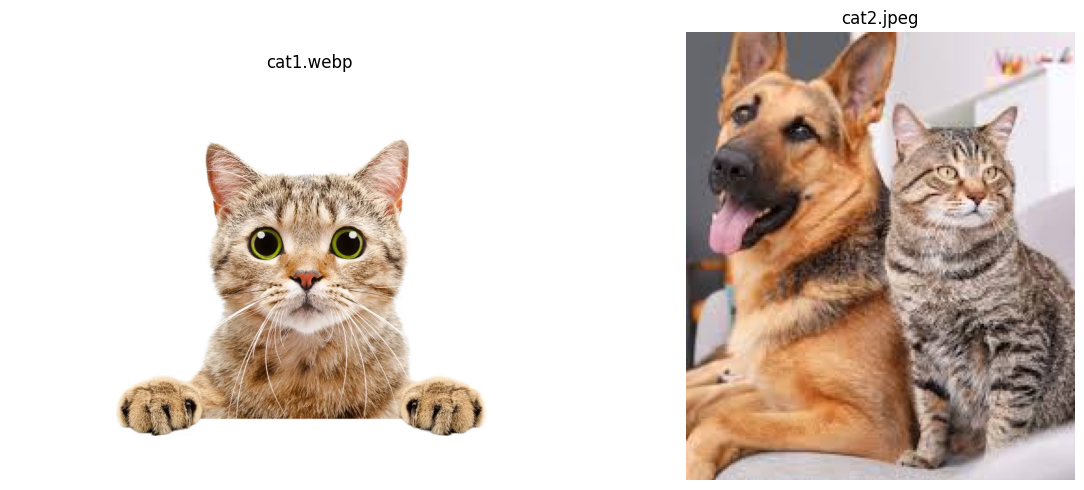

In [3]:
images = []
for path in IMAGE_PATHS:
    img = cv2.imread(str(path))
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    images.append((path.name, img))

fig, axes = plt.subplots(1, len(images), figsize=(6 * len(images), 5))
if len(images) == 1:
    axes = [axes]

for ax, (name, img) in zip(axes, images):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## گام ۲ — بارگذاری آشکارساز Haar Cascade

مدل از پیش آموزش‌دیده را با `cv2.CascadeClassifier` بارگذاری می‌کنیم.

In [4]:
cat_cascade = cv2.CascadeClassifier(str(CASCADE_PATH))
if cat_cascade.empty():
    raise FileNotFoundError(f"Could not load cascade: {CASCADE_PATH}")
print("Cascade loaded:", CASCADE_PATH.name)

Cascade loaded: haarcascade_frontalcatface_extended.xml


## گام ۳ — تشخیص و نمایش نتایج

روی تصویر خاکستری (با **بلور** برای دقت بهتر) تابع `detectMultiScale` را با پارامترهای خواسته‌شده فراخوانی می‌کنیم، مستطیل‌ها را رسم می‌کنیم و برچسب **Cat** می‌نویسیم.

cat1.webp: 1 cat face(s)
cat2.jpeg: 1 cat face(s)


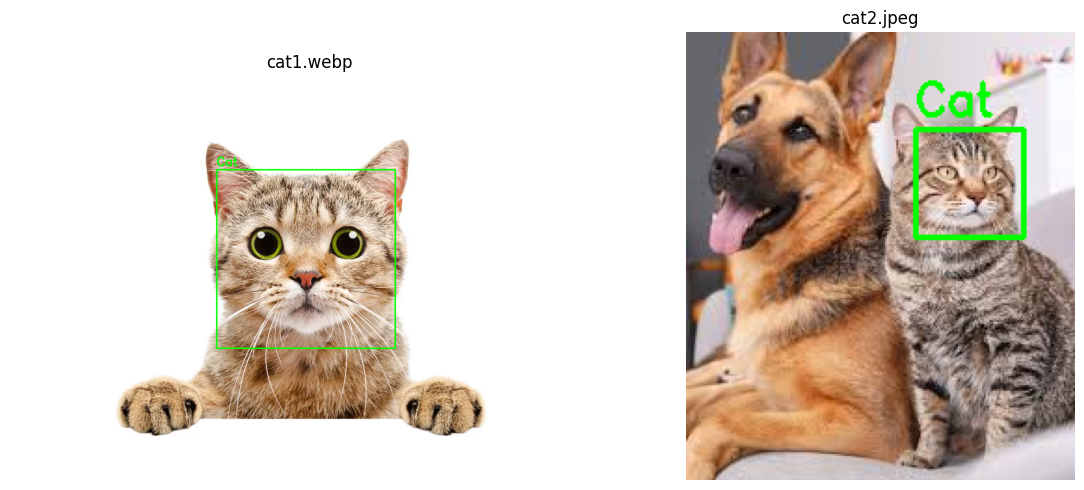

In [5]:
def run_detection(img, cascade):
    """تشخیص روی تصویر رنگی یا خاکستری؛ خروجی برای نمایش و آرایهٔ باکس‌ها."""
    if len(img.shape) == 2:
        gray = img
        vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    else:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        vis = img.copy()
    gray = cv2.GaussianBlur(gray, (9, 9), 0)
    faces = cascade.detectMultiScale(
        gray, scaleFactor=1.1, minNeighbors=5, minSize=(50, 50),
    )
    for (x, y, w, h) in faces:
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(vis, "Cat", (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    return vis, faces


def detect_cats(img, cascade):
    return run_detection(img, cascade)

results = []
for name, img in images:
    detected, faces = detect_cats(img, cat_cascade)
    results.append((name, detected, len(faces)))
    print(f"{name}: {len(faces)} cat face(s)")

fig, axes = plt.subplots(1, len(results), figsize=(6 * len(results), 5))
if len(results) == 1:
    axes = [axes]

for ax, (name, detected, _) in zip(axes, results):
    ax.imshow(cv2.cvtColor(detected, cv2.COLOR_BGR2RGB))
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

**تحلیل گام ۳ (cat1):** اگر قبلاً دو باکس تو در تو روی یک گربه دیده می‌شد، علت **تشخیص در مقیاس‌های مختلف** است. با بلور قوی‌تر `(9, 9)` جزئیات بینی/دهان کمتر برجسته می‌شود و معمولاً فقط **یک** باکس برای کل صورت باقی می‌ماند. پارامترهای `detectMultiScale` طبق دستور تمرین ثابت هستند.

## گام ۴ — مقایسهٔ ورودی رنگی و خاکستری

همان تصویر را یک‌بار **رنگی (BGR)** و یک‌بار **خاکستری** به آشکارساز می‌دهیم و تعداد و موقعیت تشخیص‌ها را مقایسه می‌کنیم.

cat1.webp — رنگی: 1 | خاکستری: 1
cat2.jpeg — رنگی: 1 | خاکستری: 1


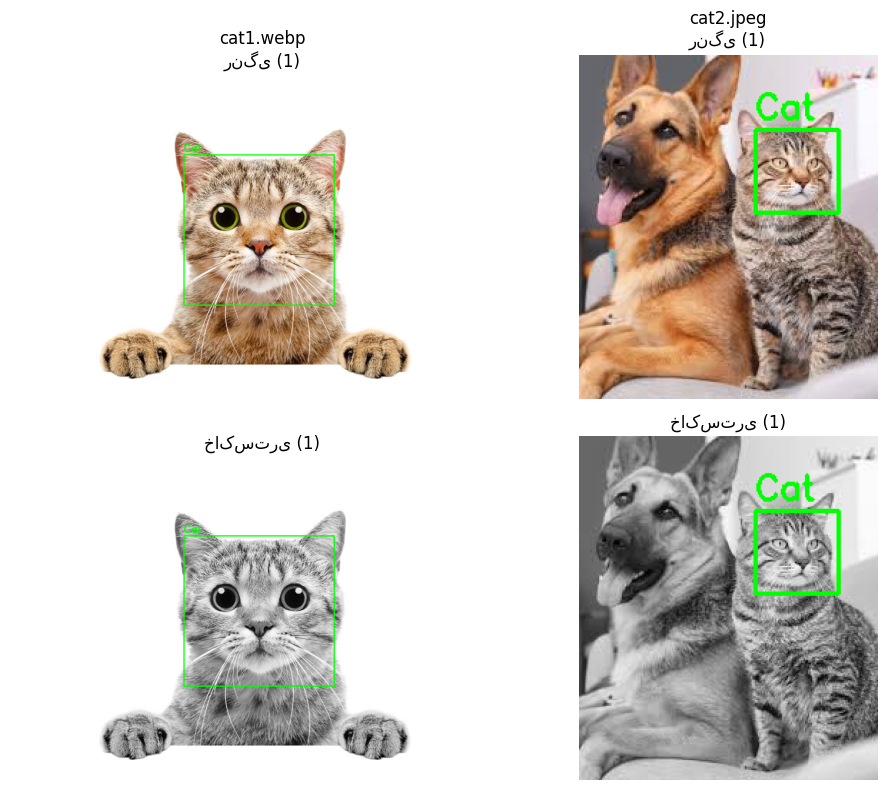

In [6]:
rows = []
for name, img in images:
    vis_color, faces_color = run_detection(img, cat_cascade)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    vis_gray, faces_gray = run_detection(gray, cat_cascade)
    rows.append((name, vis_color, len(faces_color), vis_gray, len(faces_gray)))
    print(f"{name} — رنگی: {len(faces_color)} | خاکستری: {len(faces_gray)}")

n = len(rows)
fig, axes = plt.subplots(2, n, figsize=(5 * n, 8))
if n == 1:
    axes = axes.reshape(2, 1)

for col, (name, vis_c, n_c, vis_g, n_g) in enumerate(rows):
    axes[0, col].imshow(cv2.cvtColor(vis_c, cv2.COLOR_BGR2RGB))
    axes[0, col].set_title(f"{name}\nرنگی ({n_c})")
    axes[0, col].axis("off")
    axes[1, col].imshow(cv2.cvtColor(vis_g, cv2.COLOR_BGR2RGB))
    axes[1, col].set_title(f"خاکستری ({n_g})")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

**تحلیل گام ۴:** Haar Cascade فقط از **کانال شدت روشنایی** استفاده می‌کند؛ در هر دو حالت تصویر به خاکستری + بلور تبدیل می‌شود. بنابراین معمولاً **تعداد و مختصات باکس‌ها یکسان** می‌ماند و تفاوت فقط در نحوهٔ نمایش (رنگی در برابر خاکستری) است. اگر اختلافی دیدید، احتمالاً به تفاوت جزئی در پیش‌پردازش یا نویز کانال‌ها برمی‌گردد، نه به «یادگیری رنگ» توسط مدل.

## گام ۵ — مقاومت در برابر چرخش ۹۰ درجه

تصاویر را **۹۰ درجه** می‌چرخانیم، دوباره تشخیص می‌گیریم و با حالت عادی مقایسه می‌کنیم.

cat1.webp — عادی: 1 | چرخیده ۹۰°: 0
cat2.jpeg — عادی: 1 | چرخیده ۹۰°: 0


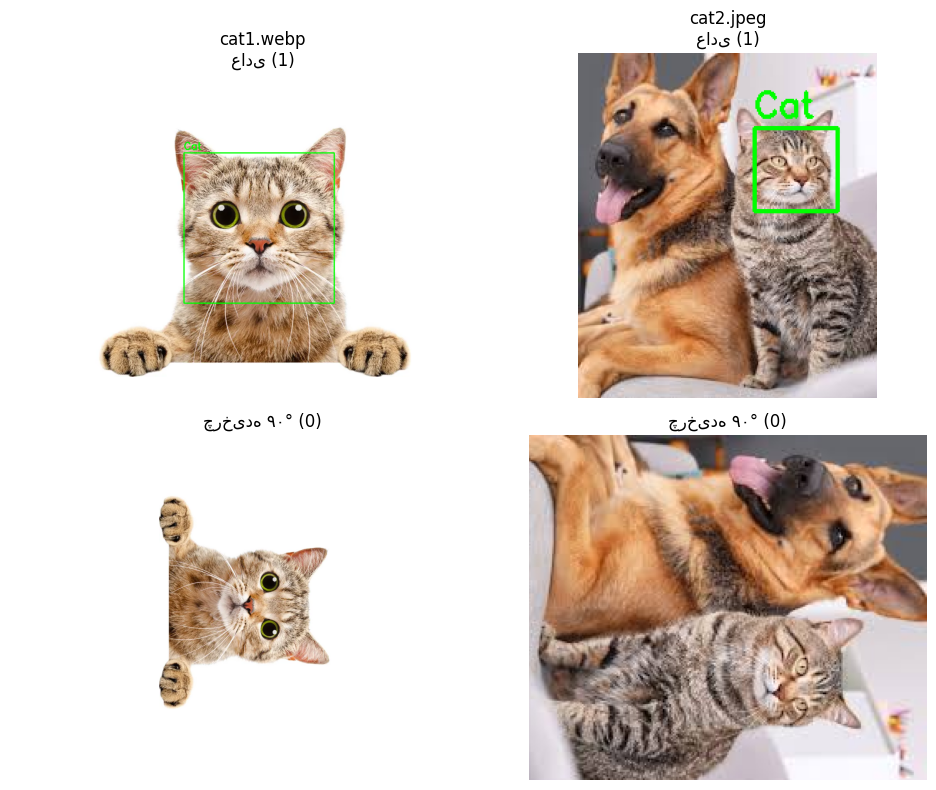

In [7]:
rotate_code = cv2.ROTATE_90_CLOCKWISE

rot_rows = []
for name, img in images:
    vis_orig, faces_orig = run_detection(img, cat_cascade)
    rotated = cv2.rotate(img, rotate_code)
    vis_rot, faces_rot = run_detection(rotated, cat_cascade)
    rot_rows.append((name, vis_orig, len(faces_orig), vis_rot, len(faces_rot)))
    print(f"{name} — عادی: {len(faces_orig)} | چرخیده ۹۰°: {len(faces_rot)}")

n = len(rot_rows)
fig, axes = plt.subplots(2, n, figsize=(5 * n, 8))
if n == 1:
    axes = axes.reshape(2, 1)

for col, (name, vis_o, n_o, vis_r, n_r) in enumerate(rot_rows):
    axes[0, col].imshow(cv2.cvtColor(vis_o, cv2.COLOR_BGR2RGB))
    axes[0, col].set_title(f"{name}\nعادی ({n_o})")
    axes[0, col].axis("off")
    axes[1, col].imshow(cv2.cvtColor(vis_r, cv2.COLOR_BGR2RGB))
    axes[1, col].set_title(f"چرخیده ۹۰° ({n_r})")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

**تحلیل گام ۵:** این cascade برای **صورت frontal** آموزش دیده و نسبت به **چرخش مقاوم نیست**. پس از چرخش ۹۰ درجه، زاویهٔ صورت با الگوی آموزشی هم‌خوان نیست؛ اغلب **تشخیص کمتر، باکس اشتباه، یا عدم تشخیص** دیده می‌شود. برای چرخش باید از روش‌های مقاوم‌تر (مثلاً چرخش تصویر در چند زاویه، یا مدل‌های عمیق) استفاده کرد.